# 10 · Brand24's rule, reconstructed

What the reach column looks like on X, Facebook and Instagram, how far it is from real views, and what happens if the same simple rule gets its constants from the data. Not confirmed by Brand24: Brand24 told us the column is only indicative.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, brand24_rule as br

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
d = br.load(ROOT); d[['platform', 'F', 'likes', 'comments', 'shares', 'E', 'R', 'view_count']].groupby('platform').median().reindex(br.ORDER).round(1)

,F,likes,comments,shares,E,R,view_count
platform,,,,,,,
tiktok,1447.0,32.0,2.0,1.0,36.5,723.0,723.0
youtube,27850.0,7.0,1.0,0.0,7.0,397.0,411.0
twitter,373.0,0.0,1.0,0.0,0.0,141.0,26.0
facebook,60080.0,3.0,0.0,0.0,4.0,2200.0,NaN
instagram,7694.0,1.0,0.0,NaN,1.0,20.0,NaN


## 1 · Reach per reaction and per follower

In [3]:
br.per_reaction(d)

,platform,bin,n,mode,median
0,facebook,1-10,956,100.0,273.6
1,facebook,11-100,577,100.0,100.0
2,facebook,>100,302,100.0,100.0
3,instagram,1-10,963,20.0,20.0
4,instagram,11-100,376,20.0,20.0
5,instagram,>100,76,20.0,45.0
6,tiktok,1-10,547,40.0,48.3
7,tiktok,11-100,1101,10.0,18.8
8,tiktok,>100,759,10.0,15.7
9,twitter,1-10,782,700.0,700.0


In [4]:
br.per_follower(d)

,platform,bin,n,mode,median
0,facebook,<10k,214,0.10,0.100
1,facebook,10k-50k,98,0.06,0.060
2,facebook,50k-100k,32,0.05,0.050
3,facebook,100k-1M,87,0.04,0.040
4,facebook,>1M,12,0.02,0.020
5,tiktok,<10k,66,0.00,0.722
6,tiktok,10k-50k,8,0.00,0.001
7,twitter,<10k,1220,0.10,0.099
8,twitter,10k-50k,58,0.09,0.090
9,twitter,50k-100k,8,0.07,0.070


## 2 · How much of the column does the rule reproduce?
X: larger of 700 per reaction (300 per reaction above 10 reactions) and a stepwise constant times followers. Facebook: 100 per reaction and the same steps. Instagram: 20 per reaction.

In [5]:
fit = br.rule_fit(d); fit.round(3)

,platform,rows,followers part wins,matched by the rule,with reactions
0,X (Twitter),2500,0.571,0.977,0.367
1,Facebook,2500,0.555,0.958,0.734
2,Instagram,2500,0.000,0.983,0.566


## 3 · The assumed multiplier against real views

,platform,posts,reach per reaction,views per reaction,low,high
0,TikTok,2407,21.3,21.3,11.9,42.2
1,YouTube,1778,19.8,19.8,10.0,44.0
2,X (Twitter),917,700.0,27.0,11.6,75.9
3,Facebook,1835,108.0,NaN,NaN,NaN
4,Instagram,1415,20.0,NaN,NaN,NaN


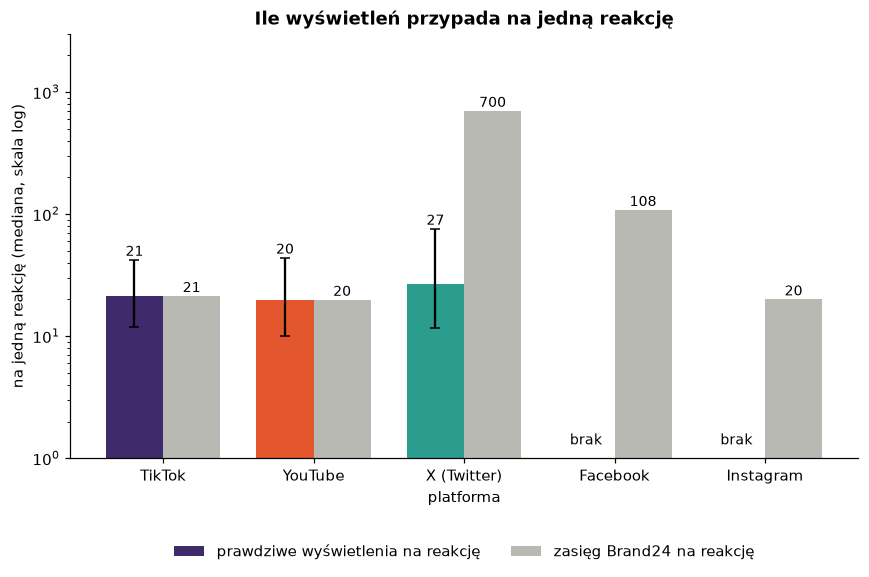

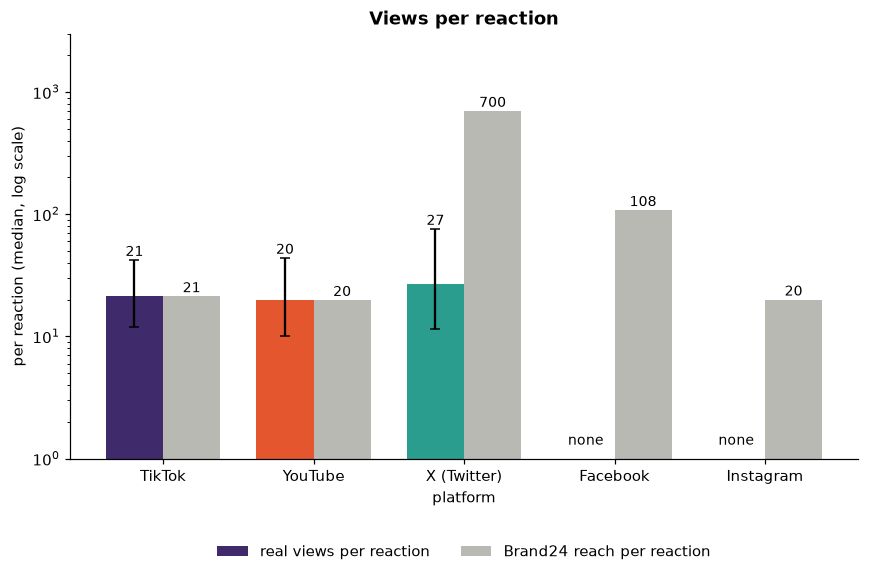

In [6]:
rv = br.real_vs_rule(d); display(rv.round(1))
for l in ('pl', 'en'): br.plot_real_vs_rule(rv, FIG / f'per_reaction_{l}.png', l)

## 4 · The same rule with constants learned from the data
views = max(k × reactions, c × followers), both constants from training brands.

In [7]:
cr = br.corrected_rule(d); cr.round(3).T

,0,1,2
platform,TikTok,YouTube,X (Twitter)
k per reaction,21.286,19.764,27.0
c per follower,0.433,0.009,0.056
corrected rule MAE,0.534,0.604,0.72
low,0.509,0.576,0.68
high,0.558,0.634,0.761
Brand24 MAE (same rows),NaN,NaN,1.083
corrected rule MAE (same rows),NaN,NaN,0.676
gain,NaN,NaN,0.407
gain low,NaN,NaN,0.37


## 5 · Where the rule's error on X comes from

In [8]:
sp = br.x_error_split(d); sp.round(3)

,posts,n,MAE,low,high,bias
0,with reactions,830,1.356,1.310,1.404,-1.349
1,without reactions,809,0.802,0.759,0.849,-0.320


## Takeaways
- **The column is a rule:** the larger of a multiplier × reactions and a stepwise constant × followers reproduces 98% of X, 96% of Facebook and 98% of Instagram within 2%. The multiplier is 700 per reaction on X (300 above 10 reactions), 100 on Facebook, 20 on Instagram. Reconstructed by us, not confirmed by Brand24.
- **Real views per reaction are close on three different platforms:** medians 21 TikTok, 20 YouTube, 27 X (interquartile ranges about 10-75). Instagram's 20 matches them, Facebook's 100 is about 5 times higher, X's 700 about 26 times higher.
- **Where the rule's error on X comes from:** posts with reactions (MAE 1.36) rather than posts without (0.80).
- **Learning the two constants from the data** lowers the error on X from 1.08 to 0.68 with the same simple form; a full model reaches 0.47. Views and reach may not be the same concept, which is still an open question to Brand24.

In [9]:
json.dump({"per_reaction": br.per_reaction(d).astype({"bin": str}).to_dict("records"), "per_follower": br.per_follower(d).astype({"bin": str}).to_dict("records"), "fit": fit.to_dict("records"), "real_vs_rule": rv.to_dict("records"), "corrected": cr.to_dict("records"), "x_split": sp.to_dict("records")}, open(ROOT / "data" / "processed" / "rule_numbers.json", "w"), indent=1, default=float)